In [1]:
from pathlib import Path
import gzip
import hashlib
import json
import platform
import random
import struct
import time
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, log_loss

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists() and (p / "notebooks").is_dir())
RAW = ROOT / "data" / "raw"
SPLITS = ROOT / "data" / "splits"
RESULTS = ROOT / "results" / "cnn-stability"
RESULTS.mkdir(parents=True, exist_ok=True)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
CLASS_NAMES = np.array(["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"])
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
environment = {"python": platform.python_version(), "device": str(DEVICE), **{name: version(name) for name in ("numpy", "pandas", "scikit-learn", "torch")}}
display(pd.Series(environment, name="Environment"))

python          3.12.0
device             mps
numpy            2.5.4
pandas           3.0.6
scikit-learn     1.9.1
torch           2.14.1
Name: Environment, dtype: str

In [2]:
def read_idx(path):
    with gzip.open(path, "rb") as stream:
        payload = stream.read()
    zero_a, zero_b, dtype_code, dimensions = struct.unpack(">BBBB", payload[:4])
    if (zero_a, zero_b, dtype_code) != (0, 0, 8) or dimensions not in (1, 3):
        raise ValueError(f"Invalid IDX header: {path.name}")
    offset = 4 + 4 * dimensions
    shape = struct.unpack(">" + "I" * dimensions, payload[4:offset])
    values = np.frombuffer(payload, dtype=np.uint8, offset=offset)
    if values.size != np.prod(shape):
        raise ValueError(f"Invalid IDX payload size: {path.name}")
    return values.reshape(shape)

metadata_path = SPLITS / "train-validation-v1.json"
split_path = SPLITS / "train-validation-v1.npz"
if not metadata_path.exists() or not split_path.exists():
    raise FileNotFoundError("Run 01-data-exploration.ipynb first")
split_metadata = json.loads(metadata_path.read_text())
split_sha256 = hashlib.sha256(split_path.read_bytes()).hexdigest()
assert split_sha256 == split_metadata["split_file_sha256"]
training_files = [record for record in split_metadata["files"] if record["filename"].startswith("train-")]
for record in training_files:
    assert hashlib.sha256((RAW / record["filename"]).read_bytes()).hexdigest() == record["sha256"]
images = read_idx(RAW / "train-images-idx3-ubyte.gz")
labels = read_idx(RAW / "train-labels-idx1-ubyte.gz")
with np.load(split_path, allow_pickle=False) as saved:
    train_indices = saved["train_indices"]
    validation_indices = saved["validation_indices"]
assert images.shape == (60000, 28, 28) and labels.shape == (60000,)
assert np.array_equal(np.sort(np.concatenate([train_indices, validation_indices])), np.arange(len(labels)))
assert np.intersect1d(train_indices, validation_indices).size == 0
X_train = torch.from_numpy(images[train_indices].astype(np.float32) / 255.0).unsqueeze(1)
X_validation = torch.from_numpy(images[validation_indices].astype(np.float32) / 255.0).unsqueeze(1)
y_train = labels[train_indices]
y_validation = labels[validation_indices]
train_dataset = TensorDataset(X_train, torch.from_numpy(y_train.astype(np.int64)))
validation_dataset = TensorDataset(X_validation, torch.from_numpy(y_validation.astype(np.int64)))
BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, generator=torch.Generator().manual_seed(SEED))
train_eval_loader = DataLoader(train_dataset, batch_size=512, shuffle=False, num_workers=0)
validation_loader = DataLoader(validation_dataset, batch_size=512, shuffle=False, num_workers=0)
assert tuple(X_train.shape) == (48000, 1, 28, 28)
assert tuple(X_validation.shape) == (12000, 1, 28, 28)
assert torch.isfinite(X_train).all() and torch.isfinite(X_validation).all()
assert 0 <= X_train.min() <= X_train.max() <= 1
assert 0 <= X_validation.min() <= X_validation.max() <= 1
display(pd.DataFrame({"split": ["Training", "Validation"], "shape": [str(tuple(X_train.shape)), str(tuple(X_validation.shape))]}))

,split,shape
0,Training,"(48000, 1, 28, 28)"
1,Validation,"(12000, 1, 28, 28)"


In [3]:
CONFIGS = [
    {"name": "wider", "channels": [32, 64], "hidden": 128, "weight_decay": 0.0},
    {"name": "wider_weight_decay", "channels": [32, 64], "hidden": 128, "weight_decay": 0.0001},
]
LEARNING_RATE = 0.001
MAX_EPOCHS = 30
PATIENCE = 5
criterion = nn.CrossEntropyLoss()

def build_model(config):
    first, second = config["channels"]
    return nn.Sequential(
        nn.Conv2d(1, first, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(first, second, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(second * 7 * 7, config["hidden"]), nn.ReLU(), nn.Dropout(0.25), nn.Linear(config["hidden"], 10),
    )

def reset_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

display(pd.DataFrame(CONFIGS))
ADDITIONAL_SEEDS = [7, 123]
ALL_SEEDS = [42, *ADDITIONAL_SEEDS]

,name,channels,hidden,weight_decay
0,wider,"[32, 64]",128,0.0000
1,wider_weight_decay,"[32, 64]",128,0.0001


In [4]:
@torch.inference_mode()
def evaluate(network, loader):
    network.eval()
    total_loss = 0.0
    probabilities = []
    targets = []
    for inputs, target in loader:
        inputs, target = inputs.to(DEVICE), target.to(DEVICE)
        logits = network(inputs)
        loss = criterion(logits, target)
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite evaluation loss")
        total_loss += loss.item() * len(target)
        probabilities.append(logits.softmax(dim=1).cpu().numpy())
        targets.append(target.cpu().numpy())
    probabilities = np.concatenate(probabilities)
    targets = np.concatenate(targets)
    return total_loss / len(targets), accuracy_score(targets, probabilities.argmax(axis=1)), probabilities

In [5]:
previous_dir = ROOT / "results" / "cnn-improvements"
previous_metadata = json.loads((previous_dir / "run-metadata.json").read_text())
assert previous_metadata["split_sha256"] == split_sha256
assert previous_metadata["seed"] == 42
assert previous_metadata["max_epochs"] == MAX_EPOCHS and previous_metadata["patience"] == PATIENCE
assert previous_metadata["batch_size"] == BATCH_SIZE
assert previous_metadata["initial_learning_rate"] == LEARNING_RATE
assert previous_metadata["environment"]["torch"] == environment["torch"]
assert previous_metadata["scheduler"] == {"name": "ReduceLROnPlateau", "factor": 0.5, "patience": 2, "threshold": 0.0, "min_lr": 1e-5}
rows = []
checkpoint_records = []
histories = {}
for config in CONFIGS:
    assert config == next(c for c in previous_metadata["configs"] if c["name"] == config["name"])
    previous_row = next(r for r in previous_metadata["comparisons"] if r["name"] == config["name"])
    path = previous_dir / f"{config['name']}.pt"
    restored = build_model(config).to(DEVICE)
    restored.load_state_dict(torch.load(path, map_location="cpu", weights_only=True))
    loss, accuracy, probabilities = evaluate(restored, validation_loader)
    assert np.isclose(loss, previous_row["validation_loss"], atol=1e-6)
    assert accuracy == previous_row["validation_accuracy"]
    rows.append({**previous_row, "seed": 42})
    checkpoint_records.append({"name": config["name"], "seed": 42, "path": str(path.relative_to(ROOT)), "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
print("Revalidated both existing seed-42 checkpoints")

Revalidated both existing seed-42 checkpoints


In [6]:
for seed in ADDITIONAL_SEEDS:
    for config in CONFIGS:
        reset_seed(seed)
        run_id = f"{config['name']}-seed-{seed}"
        model = build_model(config).to(DEVICE)
        parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
        optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=config["weight_decay"])
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2, threshold=0.0, min_lr=1e-5)
        train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, generator=torch.Generator().manual_seed(seed))
        history = []
        best_loss, best_epoch, stale_epochs = float("inf"), 0, 0
        checkpoint_path = RESULTS / f"{run_id}.pt"
        start = time.perf_counter()
        for epoch in range(1, MAX_EPOCHS + 1):
            model.train()
            learning_rate = optimizer.param_groups[0]["lr"]
            for inputs, target in train_loader:
                inputs, target = inputs.to(DEVICE), target.to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                loss = criterion(model(inputs), target)
                if not torch.isfinite(loss):
                    raise RuntimeError("Non-finite training loss")
                loss.backward()
                optimizer.step()
            train_loss, train_accuracy, _ = evaluate(model, train_eval_loader)
            validation_loss, validation_accuracy, _ = evaluate(model, validation_loader)
            history.append({"epoch": epoch, "train_loss": train_loss, "validation_loss": validation_loss,
                            "train_accuracy": train_accuracy, "validation_accuracy": validation_accuracy, "learning_rate": learning_rate})
            if validation_loss < best_loss:
                best_loss, best_epoch, stale_epochs = validation_loss, epoch, 0
                torch.save({key: value.detach().cpu().clone() for key, value in model.state_dict().items()}, checkpoint_path)
            else:
                stale_epochs += 1
            scheduler.step(validation_loss)
            pd.DataFrame(history).to_csv(RESULTS / f"{run_id}-history.csv", index=False)
            print(f"{run_id} epoch {epoch:02d}: validation accuracy={validation_accuracy:.4f}, loss={validation_loss:.4f}, best epoch={best_epoch}")
            if stale_epochs >= PATIENCE:
                break
        training_seconds = time.perf_counter() - start
        model.load_state_dict(torch.load(checkpoint_path, map_location="cpu", weights_only=True))
        train_loss, train_accuracy, _ = evaluate(model, train_eval_loader)
        validation_loss, validation_accuracy, probabilities = evaluate(model, validation_loader)
        predictions = probabilities.argmax(axis=1)
        rows.append({"name": config["name"], "seed": seed, "train_accuracy": train_accuracy,
                     "validation_accuracy": validation_accuracy, "validation_loss": validation_loss,
                     "validation_macro_f1": f1_score(y_validation, predictions, average="macro"),
                     "shirt_recall": float((predictions[y_validation == 6] == 6).mean()),
                     "parameter_count": parameter_count, "selected_epoch": best_epoch, "epochs_run": len(history),
                     "training_seconds": training_seconds})
        checkpoint_records.append({"name": config["name"], "seed": seed, "path": str(checkpoint_path.relative_to(ROOT)), "sha256": hashlib.sha256(checkpoint_path.read_bytes()).hexdigest()})
        pd.DataFrame({"source_index": validation_indices, "actual": y_validation, "predicted": predictions}).to_csv(RESULTS / f"{run_id}-predictions.csv", index=False)
        histories[run_id] = history
        pd.DataFrame(rows).to_csv(RESULTS / "comparison.csv", index=False)

comparison = pd.DataFrame(rows)
comparison["accuracy_gap"] = comparison.train_accuracy - comparison.validation_accuracy
assert len(comparison) == 6
assert comparison.groupby("name").seed.nunique().eq(3).all()
display(comparison.sort_values(["seed", "name"]).round(4))

wider-seed-7 epoch 01: validation accuracy=0.8603, loss=0.3895, best epoch=1


wider-seed-7 epoch 02: validation accuracy=0.8787, loss=0.3264, best epoch=2


wider-seed-7 epoch 03: validation accuracy=0.8932, loss=0.2898, best epoch=3


wider-seed-7 epoch 04: validation accuracy=0.8917, loss=0.2955, best epoch=3


wider-seed-7 epoch 05: validation accuracy=0.9001, loss=0.2688, best epoch=5


...

wider_weight_decay-seed-123 epoch 16: validation accuracy=0.9128, loss=0.2501, best epoch=14


wider_weight_decay-seed-123 epoch 17: validation accuracy=0.9193, loss=0.2336, best epoch=14


wider_weight_decay-seed-123 epoch 18: validation accuracy=0.9261, loss=0.2322, best epoch=14


wider_weight_decay-seed-123 epoch 19: validation accuracy=0.9273, loss=0.2261, best epoch=14


,name,train_accuracy,validation_accuracy,validation_loss,validation_macro_f1,shirt_recall,parameter_count,selected_epoch,epochs_run,training_seconds,accuracy_gap,seed
2,wider,0.9675,0.9278,0.2241,0.9275,0.7842,421642,14,19,62.6598,0.0398,7
3,wider_weight_decay,0.9661,0.9239,0.2299,0.9238,0.7858,421642,17,22,73.0437,0.0422,7
0,wider,0.9567,0.9233,0.2218,0.9225,0.7208,421642,12,17,56.3279,0.0333,42
1,wider_weight_decay,0.9692,0.9228,0.2188,0.9226,0.7783,421642,17,22,72.1261,0.0465,42
4,wider,0.9474,0.9209,0.2302,0.9208,0.7692,421642,10,15,49.2192,0.0265,123
5,wider_weight_decay,0.9589,0.9235,0.2203,0.9236,0.8042,421642,14,19,60.8733,0.0354,123


In [7]:
summary = comparison.groupby("name").agg(
    seeds=("seed", "nunique"), accuracy_mean=("validation_accuracy", "mean"), accuracy_std=("validation_accuracy", "std"),
    accuracy_min=("validation_accuracy", "min"), accuracy_max=("validation_accuracy", "max"),
    macro_f1_mean=("validation_macro_f1", "mean"), macro_f1_std=("validation_macro_f1", "std"),
    shirt_recall_mean=("shirt_recall", "mean"), shirt_recall_std=("shirt_recall", "std"),
    validation_loss_mean=("validation_loss", "mean"), training_accuracy_mean=("train_accuracy", "mean"),
)
wide_accuracy = comparison.pivot(index="seed", columns="name", values="validation_accuracy")
wide_shirt = comparison.pivot(index="seed", columns="name", values="shirt_recall")
paired = pd.DataFrame({
    "weight_decay_minus_wider_accuracy_pp": 100 * (wide_accuracy.wider_weight_decay - wide_accuracy.wider),
    "weight_decay_minus_wider_shirt_recall_pp": 100 * (wide_shirt.wider_weight_decay - wide_shirt.wider),
})
display(summary.round(5))
display(paired.round(3))
print("Sample standard deviation across seeds; not a confidence interval")
print("Highest mean validation accuracy:", summary.accuracy_mean.idxmax())

,seeds,accuracy_mean,accuracy_std,accuracy_min,accuracy_max,macro_f1_mean,macro_f1_std,shirt_recall_mean,shirt_recall_std,validation_loss_mean,training_accuracy_mean
name,,,,,,,,,,,
wider,3,0.92400,0.00347,0.92092,0.92775,0.92358,0.00350,0.75806,0.03310,0.22537,0.95721
wider_weight_decay,3,0.92339,0.00059,0.92275,0.92392,0.92331,0.00062,0.78944,0.01329,0.22302,0.96475


,weight_decay_minus_wider_accuracy_pp,weight_decay_minus_wider_shirt_recall_pp
seed,,
7,-0.383,0.167
42,-0.058,5.750
123,0.258,3.500


Sample standard deviation across seeds; not a confidence interval
Highest mean validation accuracy: wider


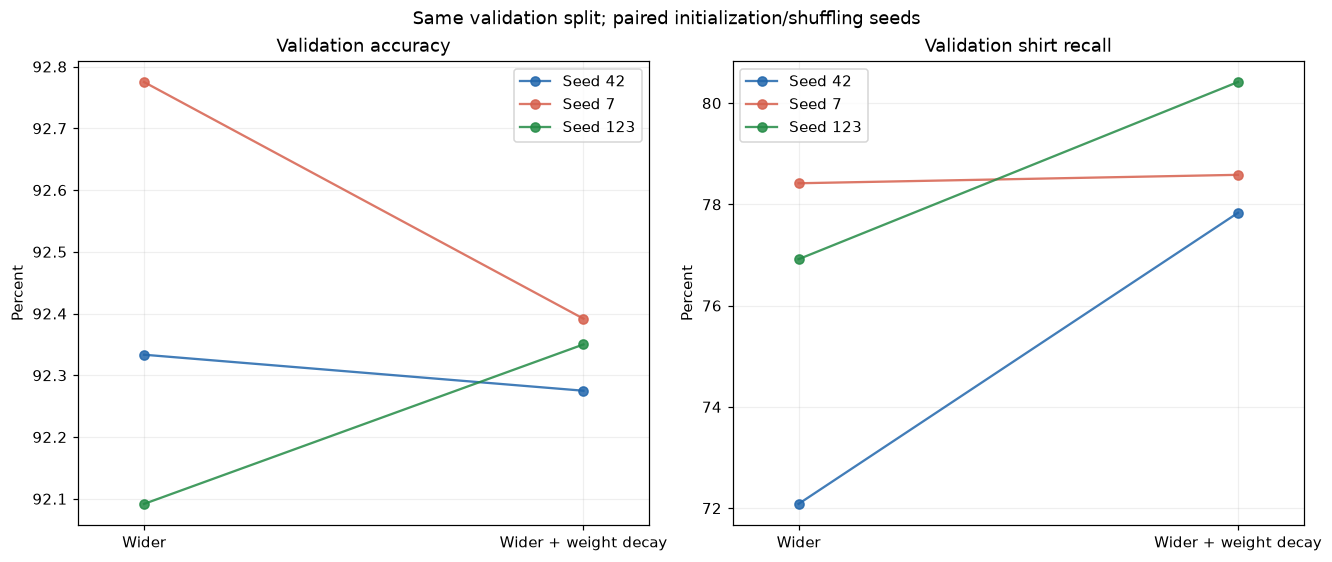

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
colors = {42: "#2166ac", 7: "#d6604d", 123: "#238b45"}
names = [config["name"] for config in CONFIGS]
for ax, metric, title in zip(axes, ["validation_accuracy", "shirt_recall"], ["Validation accuracy", "Validation shirt recall"]):
    for seed in ALL_SEEDS:
        values = comparison.loc[comparison.seed == seed].set_index("name").loc[names, metric]
        ax.plot([0, 1], 100 * values.to_numpy(), "o-", color=colors[seed], label=f"Seed {seed}", alpha=0.85)
    ax.set(xticks=[0,1], xticklabels=["Wider", "Wider + weight decay"], title=title, ylabel="Percent", xlim=(-0.15, 1.15))
    ax.legend()
    ax.grid(alpha=0.2)
fig.suptitle("Same validation split; paired initialization/shuffling seeds")
fig.savefig(RESULTS / "seed-stability.png", bbox_inches="tight")
plt.show()

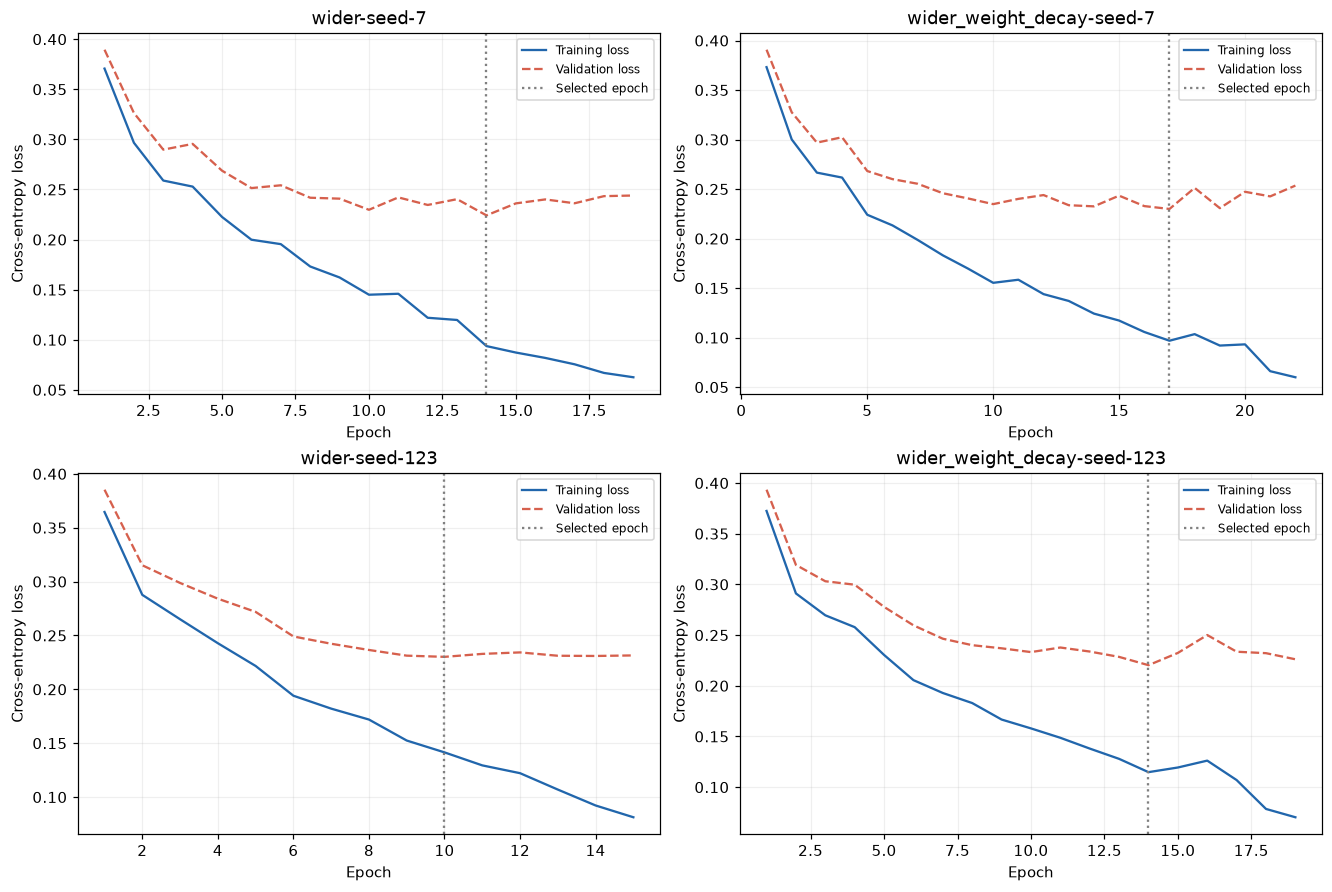

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
for seed, row_axes in zip(ADDITIONAL_SEEDS, axes):
    for config, ax in zip(CONFIGS, row_axes):
        run_id = f"{config['name']}-seed-{seed}"
        history = pd.DataFrame(histories[run_id])
        selected_epoch = int(comparison.loc[(comparison.name == config["name"]) & (comparison.seed == seed), "selected_epoch"].iloc[0])
        ax.plot(history.epoch, history.train_loss, label="Training loss", color="#2166ac")
        ax.plot(history.epoch, history.validation_loss, label="Validation loss", linestyle="--", color="#d6604d")
        ax.axvline(selected_epoch, color="gray", linestyle=":", label="Selected epoch")
        ax.set(title=run_id, xlabel="Epoch", ylabel="Cross-entropy loss")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
fig.savefig(RESULTS / "new-seed-learning-curves.png", bbox_inches="tight")
plt.show()

In [10]:
comparison.to_csv(RESULTS / "comparison.csv", index=False)
summary.to_csv(RESULTS / "summary.csv")
paired.to_csv(RESULTS / "paired-differences.csv")
metadata = {
    "configs": CONFIGS, "additional_seeds": ADDITIONAL_SEEDS, "all_seeds": ALL_SEEDS,
    "split_sha256": split_sha256, "source_files": training_files, "environment": environment,
    "previous_run_metadata_sha256": hashlib.sha256((previous_dir / "run-metadata.json").read_bytes()).hexdigest(),
    "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
    "optimizer": "Adam", "initial_learning_rate": LEARNING_RATE, "dropout": 0.25,
    "scheduler": previous_metadata["scheduler"], "checkpoint_selection": "Minimum validation loss in each run",
    "comparisons": comparison.to_dict(orient="records"), "summary": summary.reset_index().to_dict(orient="records"),
    "paired_differences": paired.reset_index().to_dict(orient="records"), "checkpoints": checkpoint_records,
    "training_count": len(y_train), "validation_count": len(y_validation), "test_evaluated": False,
    "uncertainty_scope": "Training randomness on one fixed split; sample std across three seeds, not confidence intervals",
}
(RESULTS / "run-metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
print("Saved results/cnn-stability artifacts")

Saved results/cnn-stability artifacts
